# Задача 3.1. Кривая равномерного спуска

## Постановка задачи

Найти кривую, по которой тяжёлая материальная точка под действием силы тяжести
опускается **равномерно** — с постоянной вертикальной скоростью.

Точка движется по кривой в вертикальной плоскости.
Введём систему координат:
- ось $x$ — горизонталь (вправо),
- ось $y$ — вертикаль (вверх).

**Условие равномерного спуска:**

$$\dot{y} = -u = \text{const} < 0, \qquad u > 0.$$

Требуется:
1. Составить дифференциальное уравнение кривой.
2. Проинтегрировать его и найти явный вид $y = f(x)$.
3. Построить статический график и сохранить в PNG.
4. Создать анимацию движения точки.
5. Добавить интерактивные элементы управления.

## Аналитическое решение

### 1. Уравнения движения

Пусть кривая задана уравнением $y = f(x)$. Обозначим $f'(x) = p$.

Единичный вектор касательной:

$$\hat{\tau} = \frac{(1,\; f')}{\sqrt{1+(f')^2}}.$$

Единичный вектор нормали (направление «вверх–влево»):

$$\hat{n} = \frac{(-f',\; 1)}{\sqrt{1+(f')^2}}.$$

На точку действуют:
- сила тяжести $\;(0,\; -mg)$,
- сила нормальной реакции $\;N\hat{n}$.

Второй закон Ньютона в проекциях:

$$m\ddot{x} = -N\,\frac{f'}{\sqrt{1+(f')^2}},$$

$$m\ddot{y} = N\,\frac{1}{\sqrt{1+(f')^2}} - mg.$$

### 2. Исключение нормальной реакции

Из условия $\dot{y} = -u = \text{const}$ следует $\ddot{y} = 0$.
Тогда из второго уравнения:

$$N = mg\sqrt{1+(f')^2}.$$

Подставляем в первое уравнение:

$$m\ddot{x} = -mg\sqrt{1+(f')^2}\cdot\frac{f'}{\sqrt{1+(f')^2}} = -mg\,f'.$$

Итак:

$$\boxed{\ddot{x} = -g\,f'(x).}$$

### 3. Связь ускорения с формой кривой

Из условия $\dot{y} = f'(x)\,\dot{x} = -u$ находим:

$$\dot{x} = -\frac{u}{f'(x)}.$$

Дифференцируем по времени:

$$\ddot{x} = \frac{d}{dt}\!\left(-\frac{u}{f'}\right)
= -u\cdot\frac{d}{dt}\!\left(\frac{1}{f'}\right)
= -u\cdot\left(-\frac{f''}{(f')^2}\right)\dot{x}
= \frac{u f''}{(f')^2}\cdot\left(-\frac{u}{f'}\right)
= -\frac{u^2 f''}{(f')^3}.$$

### 4. Дифференциальное уравнение кривой

Приравниваем два выражения для $\ddot{x}$:

$$-\frac{u^2 f''}{(f')^3} = -g\,f'.$$

Отсюда:

$$\boxed{f''(x) = \frac{g}{u^2}\,[f'(x)]^4.}$$

Обозначим

$$k = \frac{g}{u^2} > 0, \qquad f'' = k\,(f')^4.$$

### 5. Интегрирование

Положим $p = f'$. Тогда $p' = k\,p^4$ — уравнение с разделяющимися переменными:

$$\frac{dp}{p^4} = k\,dx
\quad\Longrightarrow\quad
-\frac{1}{3p^3} = kx + C_1.$$

Выберем начало координат так, чтобы особенность ($p\to\infty$, вертикальная
касательная) была при $x=0$. Тогда $C_1 = 0$ и

$$p^3 = -\frac{1}{3kx}, \qquad p = -\frac{1}{(3kx)^{1/3}}, \quad x > 0.$$

Интегрируем ещё раз:

$$f(x) = f(0) - \int_0^x \frac{ds}{(3ks)^{1/3}}
= f(0) - \frac{3}{2(3k)^{1/3}}\,x^{2/3}.$$

### 6. Явный вид кривой

Полагая $f(0) = y_0$ (вершина кривой), получаем:

$$\boxed{y(x) = y_0 - A\,x^{2/3}, \qquad
A = \frac{3^{2/3}}{2k^{1/3}} = \frac{3^{2/3}\,u^{2/3}}{2\,g^{1/3}}.}$$

Это **полукубическая парабола** с точкой возврата (каспом) в начале координат.

### 7. Закон движения вдоль кривой

Из $ut = A\,x^{2/3}$ получаем параметрические уравнения движения:

$$\boxed{x(t) = \left(\frac{ut}{A}\right)^{3/2}, \qquad y(t) = y_0 - ut.}$$

Проверка: $\dot{y} = -u = \text{const}$ — условие равномерного спуска выполнено.
При $t=0$ точка находится в вершине с нулевой горизонтальной скоростью
и начинает ускоряться вправо–вниз.

Горизонтальная скорость:

$$v_x = \dot{x} = (3gux)^{1/3}, \qquad v_y = -u.$$

### 8. Физический смысл параметра $A$

- $A$ растёт при увеличении $u$ (быстрый спуск требует более крутой кривой),
- $A$ убывает при увеличении $g$ (сильная тяжесть «выпрямляет» кривую).

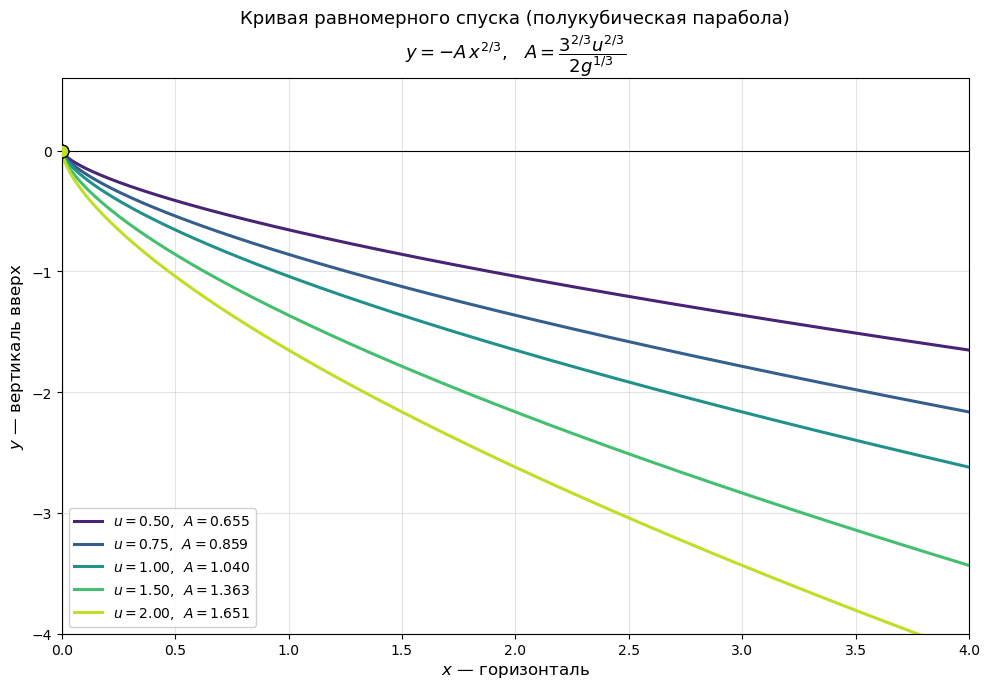

Рисунок сохранён: curve_uniform_descent.png


In [1]:
# ============================================================
# Задача 3.1. Кривая равномерного спуска
# Статическая визуализация + сохранение в PNG
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

# ---------- Вспомогательные функции ----------

def coeff_A(g, u):
    """Коэффициент A = 3^(2/3) * u^(2/3) / (2 * g^(1/3))."""
    return (3.0 ** (2.0 / 3.0)) * (u ** (2.0 / 3.0)) / (2.0 * (g ** (1.0 / 3.0)))

def curve_y(x, A, y0=0.0):
    """Уравнение кривой: y = y0 - A * x^(2/3),  x >= 0."""
    x_safe = np.maximum(x, 0.0)
    return y0 - A * np.power(x_safe, 2.0 / 3.0)

def position(t, A, u, x0=0.0, y0=0.0):
    """Положение точки на кривой в момент времени t."""
    x = x0 + (u * t / A) ** (3.0 / 2.0)
    y = y0 - u * t
    return x, y

# ---------- Параметры по умолчанию (нормированные единицы) ----------
g_default = 1.0
u_default = 1.0

# ============================================================
# Статический график: семейство кривых для разных u
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7))

x = np.linspace(0.0, 4.0, 800)
u_values = [0.5, 0.75, 1.0, 1.5, 2.0]
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(u_values)))

for u_val, color in zip(u_values, colors):
    A = coeff_A(g_default, u_val)
    y = curve_y(x, A, y0=0.0)
    ax.plot(x, y, color=color, lw=2.2,
            label=f'$u = {u_val:.2f}$,  $A = {A:.3f}$')
    # Отмечаем начальное положение (касп) в точке x=0
    ax.plot(0.0, 0.0, 'o', color=color, ms=9,
            markeredgecolor='k', markeredgewidth=0.8, zorder=5)

# Оформление
ax.set_xlim(0, 4)
ax.set_ylim(-4, 0.6)
ax.set_xlabel('$x$ — горизонталь', fontsize=12)
ax.set_ylabel('$y$ — вертикаль вверх', fontsize=12)
ax.set_title('Кривая равномерного спуска (полукубическая парабола)\n'
             r'$y = -A\,x^{2/3}$,   $A = \dfrac{3^{2/3}u^{2/3}}{2g^{1/3}}$',
             fontsize=13)
ax.grid(True, alpha=0.35)
ax.axhline(0, color='k', lw=0.8)
ax.axvline(0, color='k', lw=0.8)
ax.legend(loc='lower left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.savefig('curve_uniform_descent.png', dpi=150, bbox_inches='tight')
plt.show()
print("Рисунок сохранён: curve_uniform_descent.png")